In [2]:
import pandas as pd
from pathlib import Path

# Locate the project directory
PROJECT_DIR = Path.cwd().parent if Path.cwd().name == "python" else Path.cwd()

# Load the dataset
DATA_PATH = PROJECT_DIR / "data" / "WA_Fn-UseC_-HR-Employee-Attrition.csv"

df = pd.read_csv(DATA_PATH)

# Display the first five rows
df.head()

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


In [3]:
# Dataset dimensions
print("Dataset dimensions:", df.shape)

# Column names and data types
df.info()

# Missing values per column
print("\nMissing values per column:")
print(df.isnull().sum())

# Duplicate rows
print("\nDuplicate rows:", df.duplicated().sum())

# Summary statistics
df.describe(include="all").T

Dataset dimensions: (1470, 35)
<class 'pandas.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   Age                       1470 non-null   int64
 1   Attrition                 1470 non-null   str  
 2   BusinessTravel            1470 non-null   str  
 3   DailyRate                 1470 non-null   int64
 4   Department                1470 non-null   str  
 5   DistanceFromHome          1470 non-null   int64
 6   Education                 1470 non-null   int64
 7   EducationField            1470 non-null   str  
 8   EmployeeCount             1470 non-null   int64
 9   EmployeeNumber            1470 non-null   int64
 10  EnvironmentSatisfaction   1470 non-null   int64
 11  Gender                    1470 non-null   str  
 12  HourlyRate                1470 non-null   int64
 13  JobInvolvement            1470 non-null   int64
 14  JobLevel            

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Age,1470.0,NaN,NaN,NaN,36.92381,9.135373,18.0,30.0,36.0,43.0,60.0
Attrition,1470,2,No,1233,NaN,NaN,NaN,NaN,NaN,NaN,NaN
BusinessTravel,1470,3,Travel_Rarely,1043,NaN,NaN,NaN,NaN,NaN,NaN,NaN
DailyRate,1470.0,NaN,NaN,NaN,802.485714,403.5091,102.0,465.0,802.0,1157.0,1499.0
Department,1470,3,Research & Development,961,NaN,NaN,NaN,NaN,NaN,NaN,NaN
DistanceFromHome,1470.0,NaN,NaN,NaN,9.192517,8.106864,1.0,2.0,7.0,14.0,29.0
Education,1470.0,NaN,NaN,NaN,2.912925,1.024165,1.0,2.0,3.0,4.0,5.0
EducationField,1470,6,Life Sciences,606,NaN,NaN,NaN,NaN,NaN,NaN,NaN
EmployeeCount,1470.0,NaN,NaN,NaN,1.0,0.0,1.0,1.0,1.0,1.0,1.0
EmployeeNumber,1470.0,NaN,NaN,NaN,1024.865306,602.024335,1.0,491.25,1020.5,1555.75,2068.0


## Initial Data Inspection

### Dataset Overview

The IBM HR Analytics Employee Attrition dataset contains 1,470 employee records and 35 columns. It includes employee demographics, department and job information, compensation, job satisfaction, career progression, and attrition status.

### Data Quality Findings

- Total records: 1,470
- Total columns: 35
- Missing values detected: 0
- Duplicate rows detected: 0

All columns contain 1,470 non-null values. The initial inspection identified several constant-value columns, including EmployeeCount, StandardHours, and Over18, which will be evaluated for analytical relevance.

### Target Variable

The `Attrition` column indicates whether an employee left the organization (`Yes`) or remained (`No`). It will be the primary outcome examined throughout this project.

### Business Objective

To identify patterns and employee characteristics associated with attrition and develop data-driven insights that can help inform employee retention strategies.

### Next Steps

1. Validate categorical values and investigate constant-value columns.
2. Conduct exploratory data analysis using Python.
3. Perform SQL-based analysis of attrition patterns.
4. Develop an interactive Tableau dashboard.
5. Summarize findings and practical recommendations in the project README.

In [4]:
# Overall Employee Attrition Analysis

# Count employees who left and stayed
attrition_counts = df["Attrition"].value_counts()

employees_left = attrition_counts.get("Yes", 0)
employees_stayed = attrition_counts.get("No", 0)
total_employees = len(df)

# Calculate attrition and retention rates
attrition_rate = (employees_left / total_employees) * 100
retention_rate = (employees_stayed / total_employees) * 100

# Display results
print("OVERALL EMPLOYEE ATTRITION ANALYSIS")
print("-" * 40)
print(f"Total employees: {total_employees:,}")
print(f"Employees who left: {employees_left:,}")
print(f"Employees who stayed: {employees_stayed:,}")
print(f"Attrition rate: {attrition_rate:.2f}%")
print(f"Retention rate: {retention_rate:.2f}%")

OVERALL EMPLOYEE ATTRITION ANALYSIS
----------------------------------------
Total employees: 1,470
Employees who left: 237
Employees who stayed: 1,233
Attrition rate: 16.12%
Retention rate: 83.88%


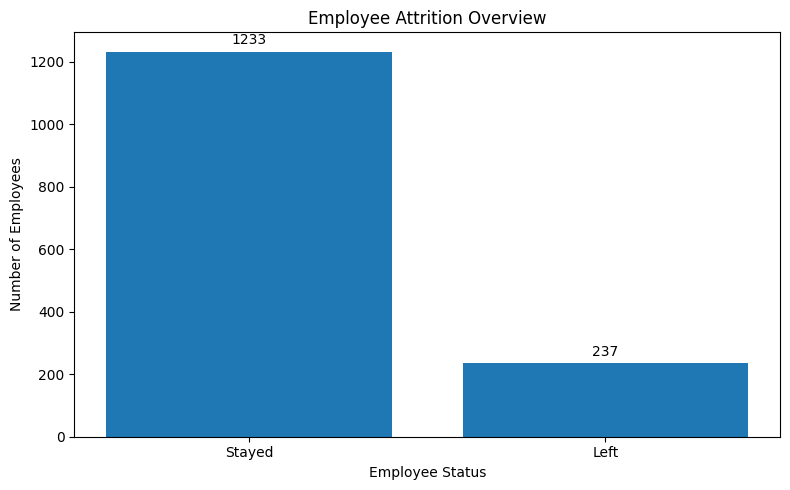

In [5]:
import matplotlib.pyplot as plt

# Prepare chart data
labels = ["Stayed", "Left"]
values = [employees_stayed, employees_left]

# Create bar chart
plt.figure(figsize=(8, 5))
bars = plt.bar(labels, values)

plt.title("Employee Attrition Overview")
plt.xlabel("Employee Status")
plt.ylabel("Number of Employees")

# Add value labels
plt.bar_label(bars, fmt="%.0f", padding=3)

plt.tight_layout()
plt.show()

## Overall Employee Attrition Analysis

### Key Results

- Total employees: 1,470
- Employees who left: 237
- Employees who stayed: 1,233
- Overall attrition rate: 16.12%
- Overall retention rate: 83.88%

### Key Finding

The analysis found that 237 of the 1,470 employees in the dataset left the organization, resulting in an overall attrition rate of 16.12%. The remaining 1,233 employees stayed, representing a retention rate of 83.88%.

### Business Implication

The overall attrition rate establishes a baseline for further investigation. Additional analysis is needed to determine whether attrition varies across departments, job roles, compensation levels, career progression, and workplace satisfaction.

### Visualization

A bar chart was created to compare the number of employees who stayed with the number who left. The visualization highlights the difference between the two employee groups.

In [6]:
# Employee attrition by department

department_attrition = (
    df.groupby("Department")
    .agg(
        TotalEmployees=("Attrition", "size"),
        EmployeesLeft=("Attrition", lambda x: (x == "Yes").sum())
    )
)

department_attrition["AttritionRate"] = (
    department_attrition["EmployeesLeft"]
    / department_attrition["TotalEmployees"]
    * 100
)

department_attrition = department_attrition.sort_values(
    "AttritionRate",
    ascending=False
)

department_attrition["AttritionRate"] = (
    department_attrition["AttritionRate"].round(2)
)

department_attrition

,TotalEmployees,EmployeesLeft,AttritionRate
Department,,,
Sales,446,92,20.63
Human Resources,63,12,19.05
Research & Development,961,133,13.84


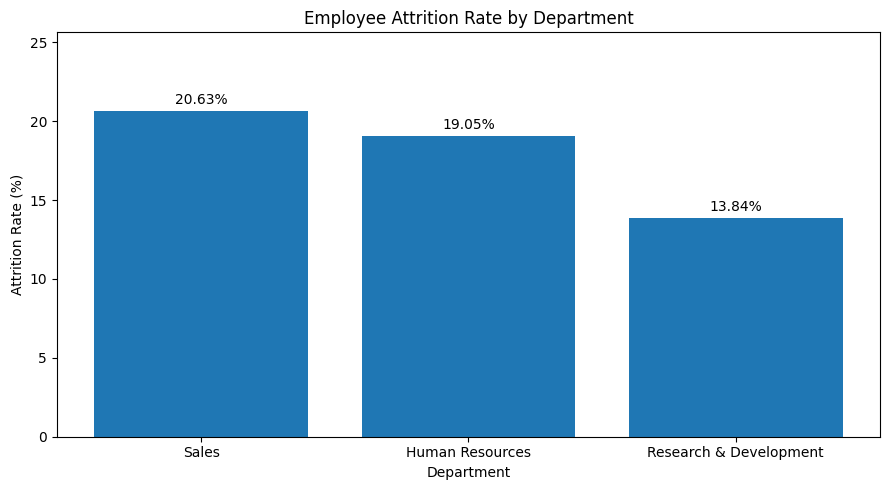

In [7]:
import matplotlib.pyplot as plt

# Reset the index to use Department as a column
plot_data = department_attrition.reset_index()

plt.figure(figsize=(9, 5))

bars = plt.bar(
    plot_data["Department"],
    plot_data["AttritionRate"]
)

plt.title("Employee Attrition Rate by Department")
plt.xlabel("Department")
plt.ylabel("Attrition Rate (%)")

plt.bar_label(bars, fmt="%.2f%%", padding=3)
plt.ylim(0, plot_data["AttritionRate"].max() + 5)

plt.tight_layout()
plt.show()

## Employee Attrition by Department

### Key Results

| Department | Total Employees | Employees Left | Attrition Rate |
|---|---:|---:|---:|
| Sales | 446 | 92 | 20.63% |
| Human Resources | 63 | 12 | 19.05% |
| Research & Development | 961 | 133 | 13.84% |

### Key Findings

Sales recorded the highest attrition rate at 20.63%, followed by Human Resources at 19.05%. Research & Development had the lowest attrition rate at 13.84%.

Despite having the lowest rate, Research & Development recorded the highest number of departures, with 133 employees leaving. This reflects its substantially larger workforce.

### Business Implications

HR may want to investigate the factors associated with attrition in Sales and Human Resources. Further analysis should examine job roles, compensation, overtime, job satisfaction, and career progression before recommending specific retention measures.

### Visualization

A bar chart compares employee attrition rates across the three departments, making differences in departmental rates easier to identify.

In [8]:
# Employee attrition by job role

job_role_attrition = (
    df.groupby("JobRole")
    .agg(
        TotalEmployees=("Attrition", "size"),
        EmployeesLeft=("Attrition", lambda x: (x == "Yes").sum())
    )
)

# Calculate attrition rate for each job role
job_role_attrition["AttritionRate"] = (
    job_role_attrition["EmployeesLeft"]
    / job_role_attrition["TotalEmployees"]
    * 100
)

# Sort from highest to lowest attrition rate
job_role_attrition = job_role_attrition.sort_values(
    "AttritionRate",
    ascending=False
)

# Round the attrition rates
job_role_attrition["AttritionRate"] = (
    job_role_attrition["AttritionRate"].round(2)
)

job_role_attrition

,TotalEmployees,EmployeesLeft,AttritionRate
JobRole,,,
Sales Representative,83,33,39.76
Laboratory Technician,259,62,23.94
Human Resources,52,12,23.08
Sales Executive,326,57,17.48
Research Scientist,292,47,16.10
Manufacturing Director,145,10,6.90
Healthcare Representative,131,9,6.87
Manager,102,5,4.90
Research Director,80,2,2.50


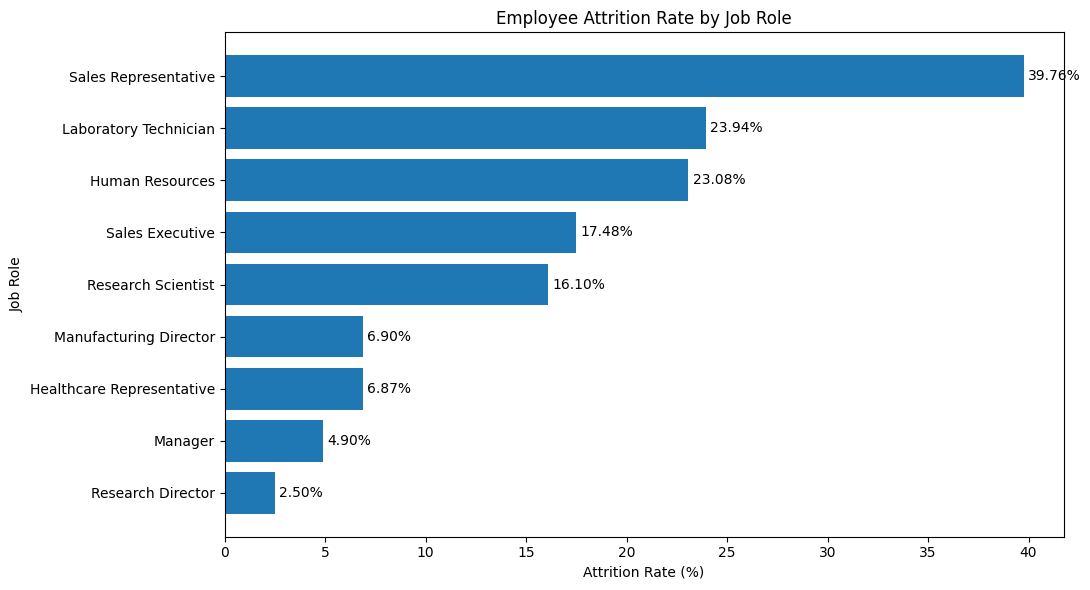

In [9]:
import matplotlib.pyplot as plt

# Prepare the data for plotting
plot_data = job_role_attrition.reset_index()

plt.figure(figsize=(11, 6))

bars = plt.barh(
    plot_data["JobRole"],
    plot_data["AttritionRate"]
)

plt.title("Employee Attrition Rate by Job Role")
plt.xlabel("Attrition Rate (%)")
plt.ylabel("Job Role")

# Put the highest rate at the top
plt.gca().invert_yaxis()

plt.bar_label(bars, fmt="%.2f%%", padding=3)
plt.tight_layout()
plt.show()

## Employee Attrition by Job Role

### Key Results

| Job Role | Total Employees | Employees Left | Attrition Rate |
|---|---:|---:|---:|
| Sales Representative | 83 | 33 | 39.76% |
| Laboratory Technician | 259 | 62 | 23.94% |
| Human Resources | 52 | 12 | 23.08% |
| Sales Executive | 326 | 57 | 17.48% |
| Research Scientist | 292 | 47 | 16.10% |
| Manufacturing Director | 145 | 10 | 6.90% |
| Healthcare Representative | 131 | 9 | 6.87% |
| Manager | 102 | 5 | 4.90% |
| Research Director | 80 | 2 | 2.50% |

### Key Findings

Sales Representatives recorded the highest attrition rate at 39.76%, followed by Laboratory Technicians at 23.94% and Human Resources employees at 23.08%.

Research Directors recorded the lowest attrition rate at 2.50%. Managers also had a relatively low rate of 4.90%.

Sales Representatives had the highest attrition rate, while Laboratory Technicians recorded the largest number of departures among these two roles, with 62 employees leaving.

### Business Implications

The results suggest that Sales Representatives and Laboratory Technicians warrant further investigation. Subsequent analysis should examine compensation, overtime, job satisfaction, tenure, and career progression to identify factors associated with attrition.

These findings describe associations within the dataset and do not establish the causes of employee departures.

### Visualization

A horizontal bar chart compares attrition rates across all nine job roles, ranked from highest to lowest.

In [10]:
# Monthly income by attrition status

income_by_attrition = (
    df.groupby("Attrition")["MonthlyIncome"]
    .agg(["count", "mean", "median"])
    .round(2)
)

income_by_attrition

,count,mean,median
Attrition,,,
No,1233,6832.74,5204.0
Yes,237,4787.09,3202.0


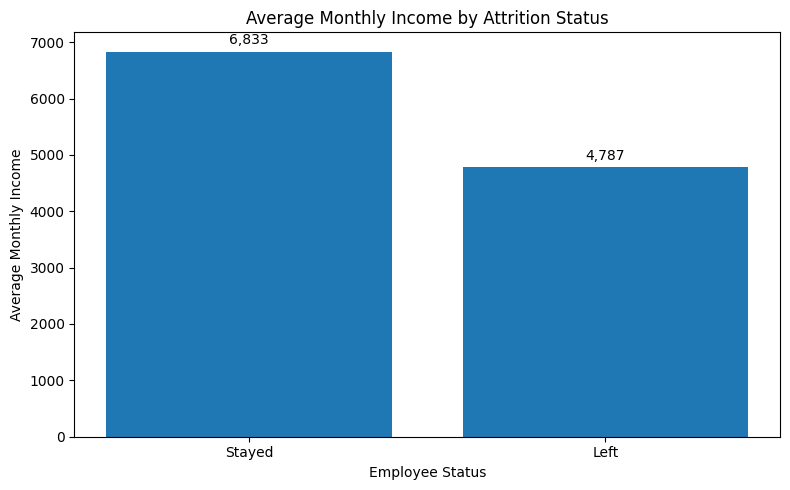

In [11]:
import matplotlib.pyplot as plt

# Compare average monthly income
mean_income = df.groupby("Attrition")["MonthlyIncome"].mean()
mean_income = mean_income.reindex(["No", "Yes"])

plt.figure(figsize=(8, 5))

bars = plt.bar(
    ["Stayed", "Left"],
    mean_income.values
)

plt.title("Average Monthly Income by Attrition Status")
plt.xlabel("Employee Status")
plt.ylabel("Average Monthly Income")

plt.bar_label(
    bars,
    labels=[f"{value:,.0f}" for value in mean_income.values],
    padding=3
)

plt.tight_layout()
plt.show()

## Monthly Income Analysis by Attrition Status

### Key Results

| Metric | Stayed | Left |
|---|---:|---:|
| Number of employees | 1,233 | 237 |
| Average monthly income | 6,832.74 | 4,787.09 |
| Median monthly income | 5,204.00 | 3,202.00 |

### Key Finding

Employees who left had an average monthly income of 4,787.09, compared with 6,832.74 among employees who stayed. This represents a difference of 2,045.65 in average monthly income.

The median income was also lower among employees who left, at 3,202 compared with 5,204 among employees who stayed.

### Business Implications

The results indicate an association between lower monthly income and employee attrition in this dataset. However, income alone cannot explain why employees leave. Job role, job level, tenure, and other workplace factors may also contribute to the observed difference.

Further analysis is needed before drawing conclusions or recommending compensation changes.

### Visualization

A bar chart compares average monthly income between employees who stayed and those who left.

In [12]:
# Analyze work experience by attrition status

tenure_by_attrition = (
    df.groupby("Attrition")
    .agg(
        EmployeeCount=("EmployeeNumber", "count"),
        AvgYearsAtCompany=("YearsAtCompany", "mean"),
        MedianYearsAtCompany=("YearsAtCompany", "median"),
        AvgTotalWorkingYears=("TotalWorkingYears", "mean"),
        AvgYearsInCurrentRole=("YearsInCurrentRole", "mean")
    )
    .round(2)
)

tenure_by_attrition

,EmployeeCount,AvgYearsAtCompany,MedianYearsAtCompany,AvgTotalWorkingYears,AvgYearsInCurrentRole
Attrition,,,,,
No,1233,7.37,6.0,11.86,4.48
Yes,237,5.13,3.0,8.24,2.90


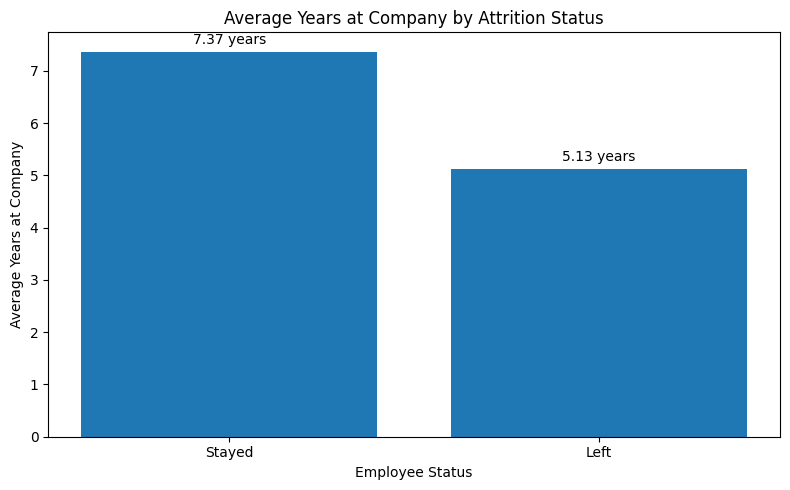

In [13]:
import matplotlib.pyplot as plt

# Compare average tenure
avg_tenure = (
    df.groupby("Attrition")["YearsAtCompany"]
    .mean()
    .reindex(["No", "Yes"])
)

plt.figure(figsize=(8, 5))

bars = plt.bar(
    ["Stayed", "Left"],
    avg_tenure.values
)

plt.title("Average Years at Company by Attrition Status")
plt.xlabel("Employee Status")
plt.ylabel("Average Years at Company")

plt.bar_label(
    bars,
    labels=[f"{value:.2f} years" for value in avg_tenure.values],
    padding=3
)

plt.tight_layout()
plt.show()

## Tenure and Work Experience Analysis

### Key Results

| Metric | Stayed | Left |
|---|---:|---:|
| Employees | 1,233 | 237 |
| Average years at company | 7.37 | 5.13 |
| Median years at company | 6.00 | 3.00 |
| Average total working years | 11.86 | 8.24 |
| Average years in current role | 4.48 | 2.90 |

### Key Findings

Employees who left had an average tenure of 5.13 years, compared with 7.37 years among employees who stayed. Their median tenure was also lower, at three years compared with six years.

Employees who left also had lower average total working experience and fewer years in their current roles.

### Business Implications

The results suggest that shorter tenure and less work experience are associated with attrition in this dataset. HR could investigate the onboarding experience, career development opportunities, and support provided to newer employees.

These findings are descriptive and do not establish the causes of employee departures.

### Visualization

A bar chart compares average years at the company between employees who stayed and employees who left.

In [14]:
# Analyze attrition by overtime status

overtime_attrition = (
    df.groupby("OverTime")
    .agg(
        TotalEmployees=("Attrition", "size"),
        EmployeesLeft=("Attrition", lambda x: (x == "Yes").sum())
    )
)

# Calculate attrition rate within each overtime group
overtime_attrition["AttritionRate"] = (
    overtime_attrition["EmployeesLeft"]
    / overtime_attrition["TotalEmployees"]
    * 100
)

overtime_attrition["AttritionRate"] = (
    overtime_attrition["AttritionRate"].round(2)
)

overtime_attrition

,TotalEmployees,EmployeesLeft,AttritionRate
OverTime,,,
No,1054,110,10.44
Yes,416,127,30.53


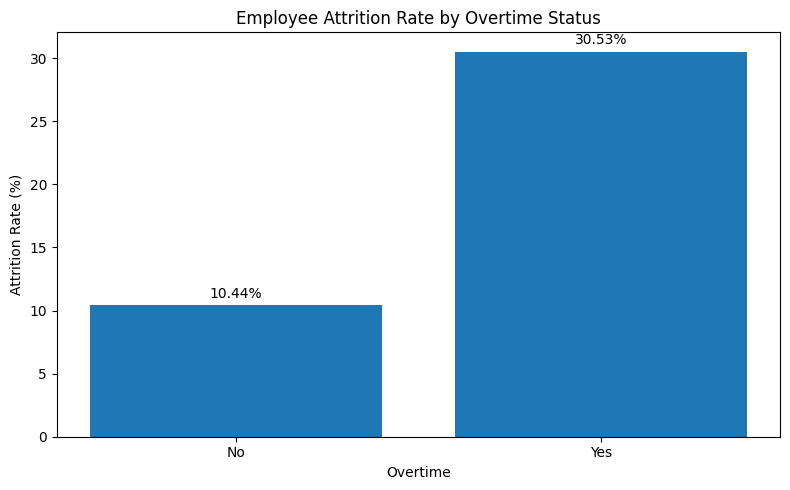

In [15]:
import matplotlib.pyplot as plt

# Prepare chart data
plot_data = overtime_attrition.reset_index()

plt.figure(figsize=(8, 5))

bars = plt.bar(
    plot_data["OverTime"],
    plot_data["AttritionRate"]
)

plt.title("Employee Attrition Rate by Overtime Status")
plt.xlabel("Overtime")
plt.ylabel("Attrition Rate (%)")

plt.bar_label(bars, fmt="%.2f%%", padding=3)

plt.tight_layout()
plt.show()

## Employee Attrition by Overtime Status

### Key Results

| Overtime Status | Total Employees | Employees Left | Attrition Rate |
|---|---:|---:|---:|
| No | 1,054 | 110 | 10.44% |
| Yes | 416 | 127 | 30.53% |

### Key Findings

Employees who worked overtime had an attrition rate of 30.53%, compared with 10.44% among employees who did not work overtime. This represents a difference of 20.09 percentage points.

The attrition rate among employees who worked overtime was approximately 2.92 times the rate among those who did not. The overtime group accounted for 127 of the 237 employee departures.

### Business Implications

The results suggest that overtime status is strongly associated with employee attrition in this dataset. HR could investigate overtime frequency, workload distribution, scheduling practices, and employee satisfaction to better understand this pattern.

The analysis is descriptive and does not establish that overtime causes employees to leave. Other employee and workplace characteristics may influence the relationship.

### Visualization

A bar chart compares attrition rates between employees who worked overtime and those who did not.

In [16]:
# Analyze attrition by job satisfaction level

satisfaction_attrition = (
    df.groupby("JobSatisfaction")
    .agg(
        TotalEmployees=("Attrition", "size"),
        EmployeesLeft=("Attrition", lambda x: (x == "Yes").sum())
    )
)

satisfaction_attrition["AttritionRate"] = (
    satisfaction_attrition["EmployeesLeft"]
    / satisfaction_attrition["TotalEmployees"]
    * 100
)

satisfaction_attrition["AttritionRate"] = (
    satisfaction_attrition["AttritionRate"].round(2)
)

satisfaction_attrition

,TotalEmployees,EmployeesLeft,AttritionRate
JobSatisfaction,,,
1,289,66,22.84
2,280,46,16.43
3,442,73,16.52
4,459,52,11.33


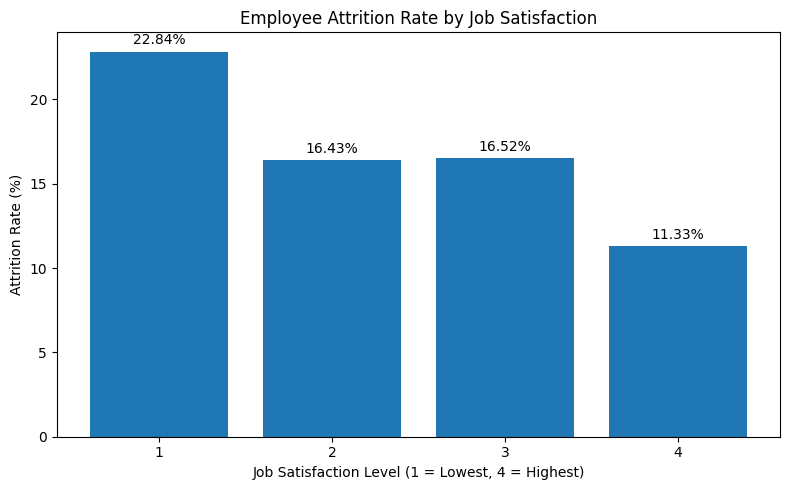

In [17]:
import matplotlib.pyplot as plt

plot_data = satisfaction_attrition.reset_index()

plt.figure(figsize=(8, 5))

bars = plt.bar(
    plot_data["JobSatisfaction"].astype(str),
    plot_data["AttritionRate"]
)

plt.title("Employee Attrition Rate by Job Satisfaction")
plt.xlabel("Job Satisfaction Level (1 = Lowest, 4 = Highest)")
plt.ylabel("Attrition Rate (%)")

plt.bar_label(bars, fmt="%.2f%%", padding=3)

plt.tight_layout()
plt.show()

## Employee Attrition by Job Satisfaction

### Key Results

| Job Satisfaction Level | Total Employees | Employees Left | Attrition Rate |
|---|---:|---:|---:|
| 1 — Lowest | 289 | 66 | 22.84% |
| 2 | 280 | 46 | 16.43% |
| 3 | 442 | 73 | 16.52% |
| 4 — Highest | 459 | 52 | 11.33% |

### Key Findings

Employees with job satisfaction level 1 had the highest attrition rate at 22.84%. Employees with level 4 had the lowest rate at 11.33%.

The difference between the lowest and highest satisfaction groups was 11.51 percentage points. Although the middle satisfaction levels had similar attrition rates, the overall pattern indicates that lower satisfaction is associated with higher attrition.

### Business Implications

HR could investigate employee feedback, workload, management support, recognition, and opportunities for professional development. These areas may help explain the observed differences, but additional analysis is needed before making conclusions about causes.

### Visualization

A bar chart compares attrition rates across the four job satisfaction levels.

In [18]:
# Analyze attrition by work-life balance

worklife_attrition = (
    df.groupby("WorkLifeBalance")
    .agg(
        TotalEmployees=("Attrition", "size"),
        EmployeesLeft=("Attrition", lambda x: (x == "Yes").sum())
    )
)

worklife_attrition["AttritionRate"] = (
    worklife_attrition["EmployeesLeft"]
    / worklife_attrition["TotalEmployees"]
    * 100
)

worklife_attrition["AttritionRate"] = (
    worklife_attrition["AttritionRate"].round(2)
)

worklife_attrition

,TotalEmployees,EmployeesLeft,AttritionRate
WorkLifeBalance,,,
1,80,25,31.25
2,344,58,16.86
3,893,127,14.22
4,153,27,17.65


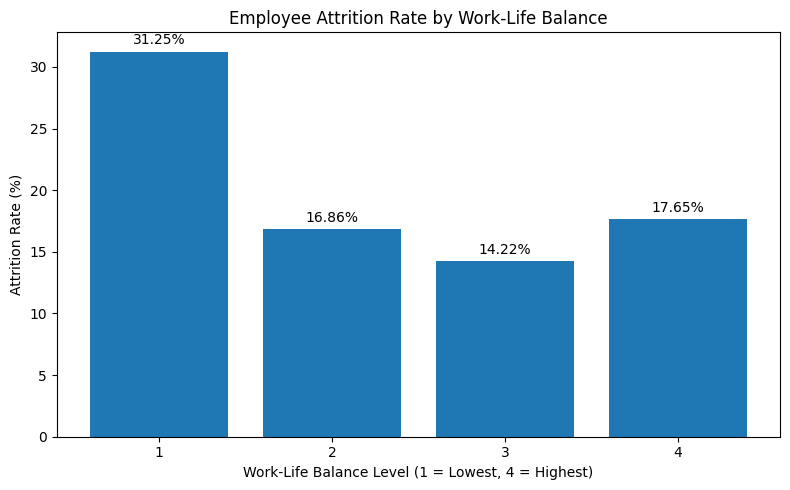

In [19]:
import matplotlib.pyplot as plt

plot_data = worklife_attrition.reset_index()

plt.figure(figsize=(8, 5))

bars = plt.bar(
    plot_data["WorkLifeBalance"].astype(str),
    plot_data["AttritionRate"]
)

plt.title("Employee Attrition Rate by Work-Life Balance")
plt.xlabel("Work-Life Balance Level (1 = Lowest, 4 = Highest)")
plt.ylabel("Attrition Rate (%)")

plt.bar_label(bars, fmt="%.2f%%", padding=3)

plt.tight_layout()
plt.show()

## Employee Attrition by Work-Life Balance

### Key Results

| Work-Life Balance Level | Total Employees | Employees Left | Attrition Rate |
|---|---:|---:|---:|
| 1 — Lowest | 80 | 25 | 31.25% |
| 2 | 344 | 58 | 16.86% |
| 3 | 893 | 127 | 14.22% |
| 4 — Highest | 153 | 27 | 17.65% |

### Key Findings

Employees with work-life balance level 1 had the highest attrition rate at 31.25%. Level 3 had the lowest rate at 14.22%, while level 4 recorded a rate of 17.65%.

The relationship is not strictly linear because the highest work-life balance rating did not correspond to the lowest attrition rate.

### Business Implications

HR could investigate workload, scheduling, overtime, employee expectations, and other workplace factors that may be associated with work-life balance and attrition.

The results are descriptive and do not establish that work-life balance causes employee departures. Differences in group sizes and other employee characteristics should be considered when interpreting the findings.

### Visualization

A bar chart compares attrition rates across the four work-life balance levels.

In [20]:
# Group employees by age range

age_bins = [0, 24, 34, 44, 54, float("inf")]
age_labels = [
    "Under 25",
    "25-34",
    "35-44",
    "45-54",
    "55+"
]

df["AgeGroup"] = pd.cut(
    df["Age"],
    bins=age_bins,
    labels=age_labels
)

# Calculate attrition by age group
age_attrition = (
    df.groupby("AgeGroup", observed=False)
    .agg(
        TotalEmployees=("Attrition", "size"),
        EmployeesLeft=("Attrition", lambda x: (x == "Yes").sum())
    )
)

age_attrition["AttritionRate"] = (
    age_attrition["EmployeesLeft"]
    / age_attrition["TotalEmployees"]
    * 100
)

age_attrition["AttritionRate"] = (
    age_attrition["AttritionRate"].round(2)
)

age_attrition

,TotalEmployees,EmployeesLeft,AttritionRate
AgeGroup,,,
Under 25,97,38,39.18
25-34,554,112,20.22
35-44,505,51,10.10
45-54,245,25,10.20
55+,69,11,15.94


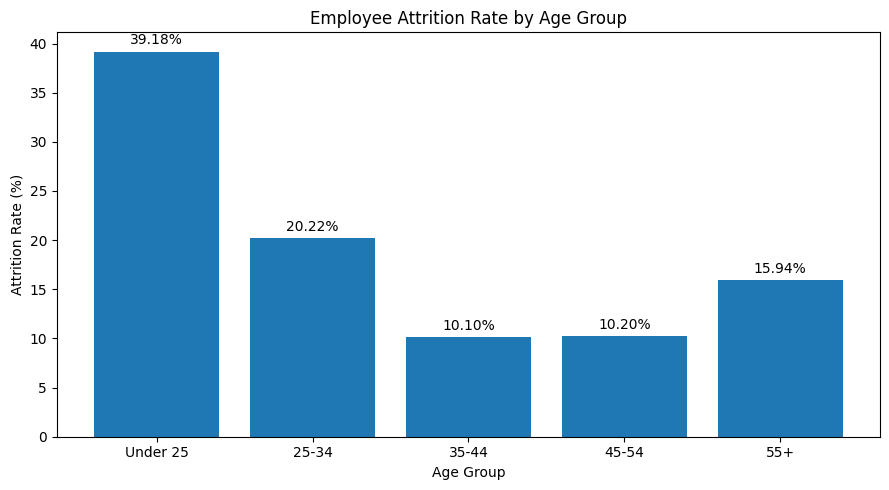

In [21]:
import matplotlib.pyplot as plt

plot_data = age_attrition.reset_index()

plt.figure(figsize=(9, 5))

bars = plt.bar(
    plot_data["AgeGroup"].astype(str),
    plot_data["AttritionRate"]
)

plt.title("Employee Attrition Rate by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Attrition Rate (%)")

plt.bar_label(bars, fmt="%.2f%%", padding=3)

plt.tight_layout()
plt.show()

## Employee Attrition by Age Group

### Key Results

| Age Group | Total Employees | Employees Left | Attrition Rate |
|---|---:|---:|---:|
| Under 25 | 97 | 38 | 39.18% |
| 25–34 | 554 | 112 | 20.22% |
| 35–44 | 505 | 51 | 10.10% |
| 45–54 | 245 | 25 | 10.20% |
| 55+ | 69 | 11 | 15.94% |

### Key Findings

Employees under 25 had the highest attrition rate at 39.18%, followed by employees aged 25–34 at 20.22%. Attrition was lowest among employees aged 35–44 at 10.10%, remaining similar at 10.20% for those aged 45–54. The rate increased to 15.94% among employees aged 55 and older.

### Business Implications

HR could investigate whether early-career employees face challenges involving career development, compensation, job expectations, onboarding, or advancement opportunities. Retention strategies should be informed by additional evidence rather than age alone.

The findings are descriptive and do not establish causation. The smaller sample sizes of the youngest and oldest age groups should also be considered when interpreting their attrition rates.

### Visualization

A bar chart compares employee attrition rates across five age groups, highlighting differences in employee retention by age.

In [22]:
# Analyze attrition by monthly income group

df["IncomeGroup"] = pd.qcut(
    df["MonthlyIncome"],
    q=4,
    labels=["Low", "Lower-Middle", "Upper-Middle", "High"]
)

income_attrition = (
    df.groupby("IncomeGroup", observed=False)
    .agg(
        TotalEmployees=("Attrition", "size"),
        EmployeesLeft=("Attrition", lambda x: (x == "Yes").sum())
    )
)

income_attrition["AttritionRate"] = (
    income_attrition["EmployeesLeft"]
    / income_attrition["TotalEmployees"]
    * 100
).round(2)

income_attrition

,TotalEmployees,EmployeesLeft,AttritionRate
IncomeGroup,,,
Low,369,108,29.27
Lower-Middle,366,52,14.21
Upper-Middle,367,39,10.63
High,368,38,10.33


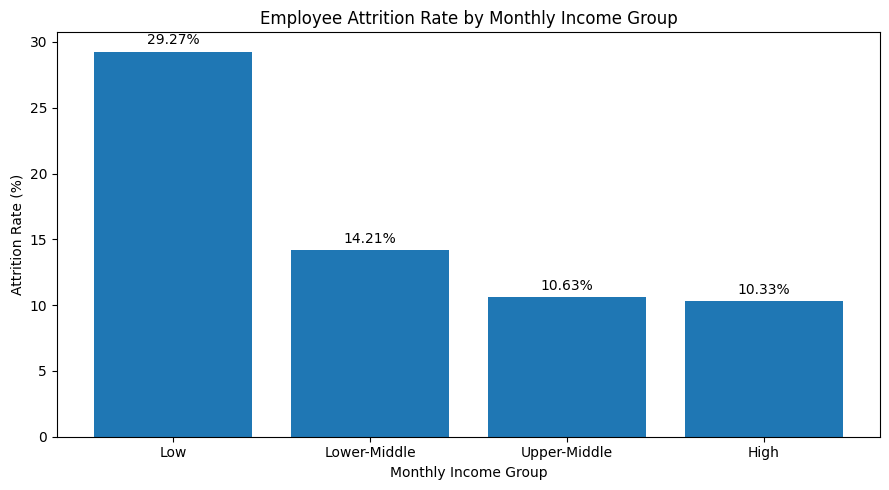

In [23]:
import matplotlib.pyplot as plt

plot_data = income_attrition.reset_index()

plt.figure(figsize=(9, 5))

bars = plt.bar(
    plot_data["IncomeGroup"].astype(str),
    plot_data["AttritionRate"]
)

plt.title("Employee Attrition Rate by Monthly Income Group")
plt.xlabel("Monthly Income Group")
plt.ylabel("Attrition Rate (%)")

plt.bar_label(bars, fmt="%.2f%%", padding=3)

plt.tight_layout()
plt.show()

## Employee Attrition by Monthly Income Group

### Key Results

| Income Group | Total Employees | Employees Left | Attrition Rate |
|---|---:|---:|---:|
| Low | 369 | 108 | 29.27% |
| Lower-Middle | 366 | 52 | 14.21% |
| Upper-Middle | 367 | 39 | 10.63% |
| High | 368 | 38 | 10.33% |

### Key Findings

The low-income group recorded the highest attrition rate at 29.27%, compared with 10.33% for the high-income group. Attrition rates declined across the income groups, with the largest difference observed between the low and lower-middle groups.

### Business Implications

HR could investigate whether compensation, salary progression, promotion opportunities, or differences in job roles contribute to the higher attrition rate among lower-income employees. Compensation adjustments should not be recommended based on this analysis alone; additional analysis is needed to identify potential contributing factors.

### Limitations

The income groups were created using quartiles of the observed monthly income distribution. These results show an association between income group and attrition, not proof that lower income causes employees to leave.

### Visualization

A bar chart compares attrition rates across four monthly income groups, showing the highest rate among lower-income employees and the lowest rate among higher-income employees.

In [24]:
# Analyze employee attrition by job level

job_level_attrition = (
    df.groupby("JobLevel")
    .agg(
        TotalEmployees=("Attrition", "size"),
        EmployeesLeft=("Attrition", lambda x: (x == "Yes").sum())
    )
)

job_level_attrition["AttritionRate"] = (
    job_level_attrition["EmployeesLeft"]
    / job_level_attrition["TotalEmployees"]
    * 100
).round(2)

job_level_attrition

,TotalEmployees,EmployeesLeft,AttritionRate
JobLevel,,,
1,543,143,26.34
2,534,52,9.74
3,218,32,14.68
4,106,5,4.72
5,69,5,7.25


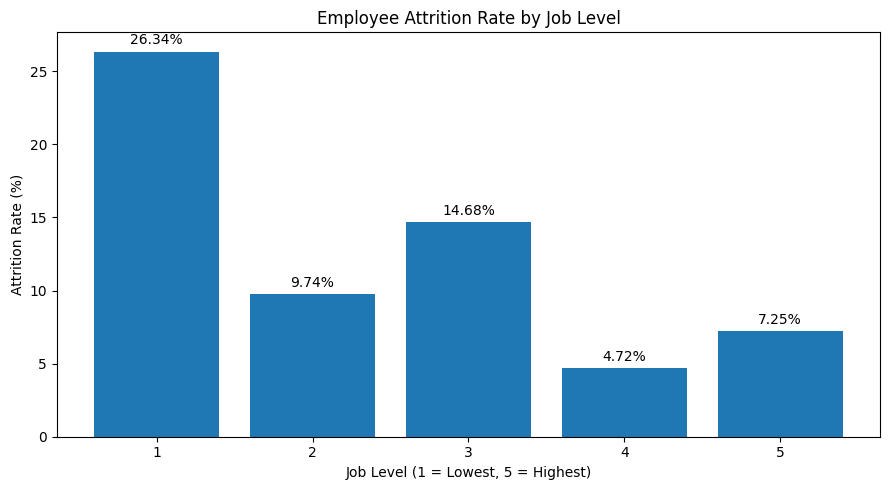

In [25]:
import matplotlib.pyplot as plt

plot_data = job_level_attrition.reset_index()

plt.figure(figsize=(9, 5))

bars = plt.bar(
    plot_data["JobLevel"].astype(str),
    plot_data["AttritionRate"]
)

plt.title("Employee Attrition Rate by Job Level")
plt.xlabel("Job Level (1 = Lowest, 5 = Highest)")
plt.ylabel("Attrition Rate (%)")

plt.bar_label(bars, fmt="%.2f%%", padding=3)

plt.tight_layout()
plt.show()

## Employee Attrition by Job Level

### Key Results

| Job Level | Total Employees | Employees Left | Attrition Rate |
|---:|---:|---:|---:|
| 1 | 543 | 143 | 26.34% |
| 2 | 534 | 52 | 9.74% |
| 3 | 218 | 32 | 14.68% |
| 4 | 106 | 5 | 4.72% |
| 5 | 69 | 5 | 7.25% |

### Key Findings

Job Level 1 recorded the highest attrition rate at 26.34%, followed by Job Level 3 at 14.68%. Job Level 4 had the lowest attrition rate at 4.72%, while Job Level 5 recorded 7.25%.

The results indicate that attrition is substantially higher among employees at the lowest job level. However, the relationship between job level and attrition is not strictly linear.

### Business Implications

HR could investigate retention challenges among entry-level employees, including onboarding, compensation, career development, job satisfaction, and access to advancement opportunities. Further analysis should consider job role, monthly income, overtime, and tenure to determine whether these factors help explain the observed differences.

### Limitations

This analysis is descriptive and does not establish that job level causes attrition. The higher job levels also contain fewer employees, so their attrition rates should be interpreted with their group sizes in mind.

### Visualization

A bar chart compares employee attrition rates across five job levels, highlighting the substantially higher rate at Job Level 1 and the lower rates at the more senior levels.

In [26]:
# Group employees by years at the company

df["TenureGroup"] = pd.cut(
    df["YearsAtCompany"],
    bins=[-1, 1, 3, 5, 10, float("inf")],
    labels=[
        "0-1 years",
        "2-3 years",
        "4-5 years",
        "6-10 years",
        "11+ years"
    ]
)

tenure_attrition = (
    df.groupby("TenureGroup", observed=False)
    .agg(
        TotalEmployees=("Attrition", "size"),
        EmployeesLeft=("Attrition", lambda x: (x == "Yes").sum())
    )
)

tenure_attrition["AttritionRate"] = (
    tenure_attrition["EmployeesLeft"]
    / tenure_attrition["TotalEmployees"].replace(0, float("nan"))
    * 100
).round(2)

tenure_attrition

,TotalEmployees,EmployeesLeft,AttritionRate
TenureGroup,,,
0-1 years,215,75,34.88
2-3 years,255,47,18.43
4-5 years,306,40,13.07
6-10 years,448,55,12.28
11+ years,246,20,8.13


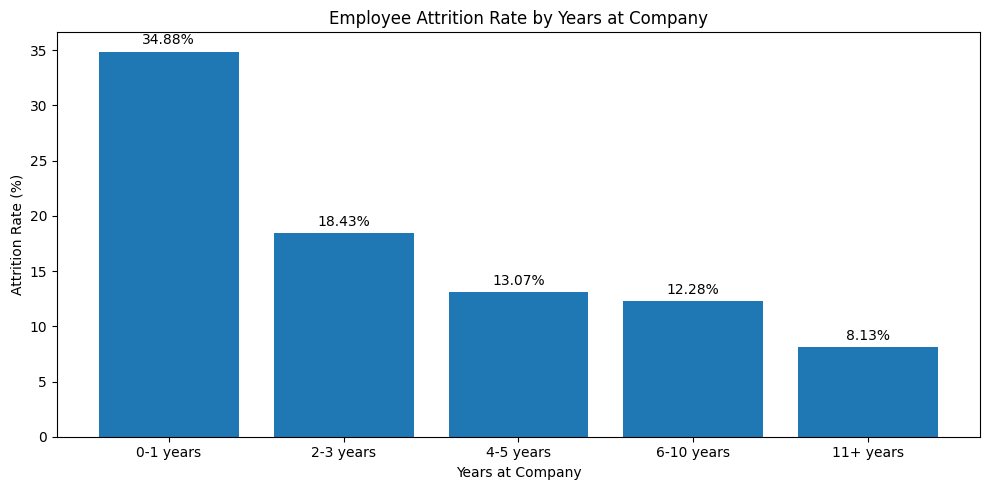

In [27]:
import matplotlib.pyplot as plt

plot_data = tenure_attrition.reset_index()

plt.figure(figsize=(10, 5))

bars = plt.bar(
    plot_data["TenureGroup"].astype(str),
    plot_data["AttritionRate"]
)

plt.title("Employee Attrition Rate by Years at Company")
plt.xlabel("Years at Company")
plt.ylabel("Attrition Rate (%)")

plt.bar_label(bars, fmt="%.2f%%", padding=3)

plt.tight_layout()
plt.show()

## Employee Attrition by Years at Company

### Key Results

| Years at Company | Total Employees | Employees Left | Attrition Rate |
|---|---:|---:|---:|
| 0–1 years | 215 | 75 | 34.88% |
| 2–3 years | 255 | 47 | 18.43% |
| 4–5 years | 306 | 40 | 13.07% |
| 6–10 years | 448 | 55 | 12.28% |
| 11+ years | 246 | 20 | 8.13% |

### Key Findings

Employees with 0–1 years of tenure recorded the highest attrition rate at 34.88%, while employees with 11 or more years at the company recorded the lowest rate at 8.13%.

The results show a general downward trend in attrition as years at the company increase. This pattern suggests that employee retention may be a particular challenge during the early stages of employment.

### Business Implications

HR could strengthen onboarding, mentorship, early-career support, manager check-ins, and employee feedback processes. Reviewing compensation, job satisfaction, overtime, and career development opportunities among newer employees may help identify actionable retention improvements.

### Limitations

The analysis is descriptive and does not establish causation. Further investigation is needed to determine whether tenure, job role, compensation, job satisfaction, or other factors contribute to the observed attrition patterns.

### Visualization

A bar chart compares attrition rates across five tenure groups. The highest rate occurs among employees with 0–1 years at the company, while the lowest occurs among employees with 11 or more years of tenure.

In [28]:
# Analyze attrition by business travel frequency

travel_attrition = (
    df.groupby("BusinessTravel")
    .agg(
        TotalEmployees=("Attrition", "size"),
        EmployeesLeft=("Attrition", lambda x: (x == "Yes").sum())
    )
)

travel_attrition["AttritionRate"] = (
    travel_attrition["EmployeesLeft"]
    / travel_attrition["TotalEmployees"]
    * 100
).round(2)

travel_attrition = travel_attrition.sort_values(
    "AttritionRate",
    ascending=False
)

travel_attrition

,TotalEmployees,EmployeesLeft,AttritionRate
BusinessTravel,,,
Travel_Frequently,277,69,24.91
Travel_Rarely,1043,156,14.96
Non-Travel,150,12,8.00


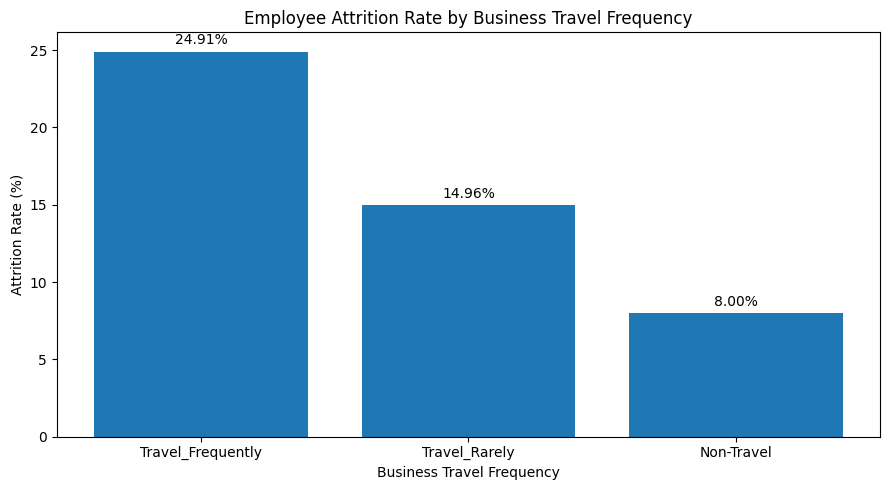

In [29]:
import matplotlib.pyplot as plt

plot_data = travel_attrition.reset_index()

plt.figure(figsize=(9, 5))

bars = plt.bar(
    plot_data["BusinessTravel"],
    plot_data["AttritionRate"]
)

plt.title("Employee Attrition Rate by Business Travel Frequency")
plt.xlabel("Business Travel Frequency")
plt.ylabel("Attrition Rate (%)")

plt.bar_label(bars, fmt="%.2f%%", padding=3)

plt.tight_layout()
plt.show()

## Employee Attrition by Business Travel Frequency

### Key Results

| Business Travel Frequency | Total Employees | Employees Left | Attrition Rate |
|---|---:|---:|---:|
| Travel Frequently | 277 | 69 | 24.91% |
| Travel Rarely | 1,043 | 156 | 14.96% |
| Non-Travel | 150 | 12 | 8.00% |

### Key Findings

Employees who travel frequently have the highest attrition rate at 24.91%, followed by employees who travel rarely at 14.96%. Employees who do not travel have the lowest attrition rate at 8.00%.

The results indicate an association between business travel frequency and employee attrition. Frequent travel may be a useful area for further investigation when evaluating employee retention.

### Business Implications

HR could examine travel schedules, workload distribution, travel recovery time, and work-life balance among frequent travelers. Employee feedback and additional analysis would help determine whether travel-related demands contribute to retention challenges.

### Limitations

This analysis is descriptive and does not establish that business travel causes attrition. Other factors, including job role, overtime, compensation, and job satisfaction, may influence the observed differences.

### Visualization

A bar chart compares attrition rates across frequent travel, rare travel, and non-travel groups. Frequent travelers have the highest observed rate, while non-travelers have the lowest.

In [30]:
# Analyze attrition by overtime and business travel

travel_overtime_attrition = (
    df.groupby(["BusinessTravel", "OverTime"])
    .agg(
        TotalEmployees=("Attrition", "size"),
        EmployeesLeft=("Attrition", lambda x: (x == "Yes").sum())
    )
)

travel_overtime_attrition["AttritionRate"] = (
    travel_overtime_attrition["EmployeesLeft"]
    / travel_overtime_attrition["TotalEmployees"]
    * 100
).round(2)

travel_overtime_attrition = travel_overtime_attrition.sort_values(
    "AttritionRate",
    ascending=False
)

travel_overtime_attrition

,,TotalEmployees,EmployeesLeft,AttritionRate
BusinessTravel,OverTime,,,
Travel_Frequently,Yes,86,36,41.86
Travel_Rarely,Yes,295,84,28.47
Non-Travel,Yes,35,7,20.00
Travel_Frequently,No,191,33,17.28
Travel_Rarely,No,748,72,9.63
Non-Travel,No,115,5,4.35


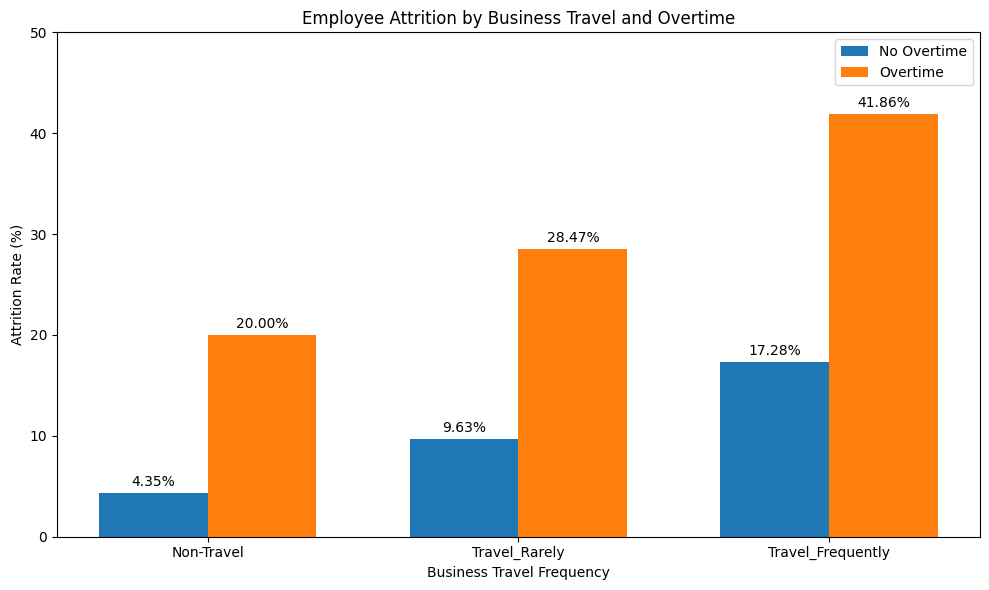

In [31]:
import matplotlib.pyplot as plt
import numpy as np

# Prepare the data for plotting
plot_data = (
    travel_overtime_attrition
    .reset_index()
    .pivot(
        index="BusinessTravel",
        columns="OverTime",
        values="AttritionRate"
    )
)

# Arrange categories in a logical order
travel_order = [
    "Non-Travel",
    "Travel_Rarely",
    "Travel_Frequently"
]

plot_data = plot_data.reindex(travel_order)

x = np.arange(len(plot_data.index))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 6))

bars_no = ax.bar(
    x - width / 2,
    plot_data["No"],
    width,
    label="No Overtime"
)

bars_yes = ax.bar(
    x + width / 2,
    plot_data["Yes"],
    width,
    label="Overtime"
)

ax.set_title(
    "Employee Attrition by Business Travel and Overtime"
)
ax.set_xlabel("Business Travel Frequency")
ax.set_ylabel("Attrition Rate (%)")
ax.set_xticks(x)
ax.set_xticklabels(plot_data.index)
ax.legend()

ax.bar_label(bars_no, fmt="%.2f%%", padding=3)
ax.bar_label(bars_yes, fmt="%.2f%%", padding=3)

ax.set_ylim(0, 50)
plt.tight_layout()
plt.show()

## Employee Attrition by Business Travel and Overtime

### Key Findings

Employees who travel frequently and work overtime have the highest observed attrition rate at 41.86%, with 36 out of 86 employees leaving. In contrast, employees who do not travel and do not work overtime have the lowest rate at 4.35%, with 5 out of 115 employees leaving.

Across all business travel categories, employees who work overtime have higher attrition rates than those who do not. The largest difference occurs among frequent travelers, where the attrition rate is 24.58 percentage points higher for employees who work overtime.

### Business Implications

HR could investigate overtime demands, travel schedules, workload distribution, and work-life balance, particularly among frequent travelers who work overtime. Employee feedback and additional analysis may help identify appropriate retention strategies.

### Limitations

This analysis identifies associations rather than causal relationships. Other factors, such as job role, compensation, age, and job satisfaction, may influence the observed attrition rates. Further analysis is needed to determine their relative contributions.

### Visualization

A grouped bar chart compares attrition rates for employees who work overtime and those who do not across three business travel categories. It highlights the highest observed attrition among frequent travelers who work overtime and the lowest among non-travelers who do not work overtime.

In [32]:
# Analyze attrition by income group and overtime

income_overtime_attrition = (
    df.groupby(["IncomeGroup", "OverTime"], observed=False)
    .agg(
        TotalEmployees=("Attrition", "size"),
        EmployeesLeft=("Attrition", lambda x: (x == "Yes").sum())
    )
)

income_overtime_attrition["AttritionRate"] = (
    income_overtime_attrition["EmployeesLeft"]
    / income_overtime_attrition["TotalEmployees"]
    * 100
).round(2)

income_overtime_attrition = income_overtime_attrition.sort_values(
    "AttritionRate",
    ascending=False
)

income_overtime_attrition

,,TotalEmployees,EmployeesLeft,AttritionRate
IncomeGroup,OverTime,,,
Low,Yes,106,62,58.49
Lower-Middle,Yes,96,25,26.04
Upper-Middle,Yes,109,21,19.27
High,Yes,105,19,18.10
Low,No,263,46,17.49
Lower-Middle,No,270,27,10.00
High,No,263,19,7.22
Upper-Middle,No,258,18,6.98


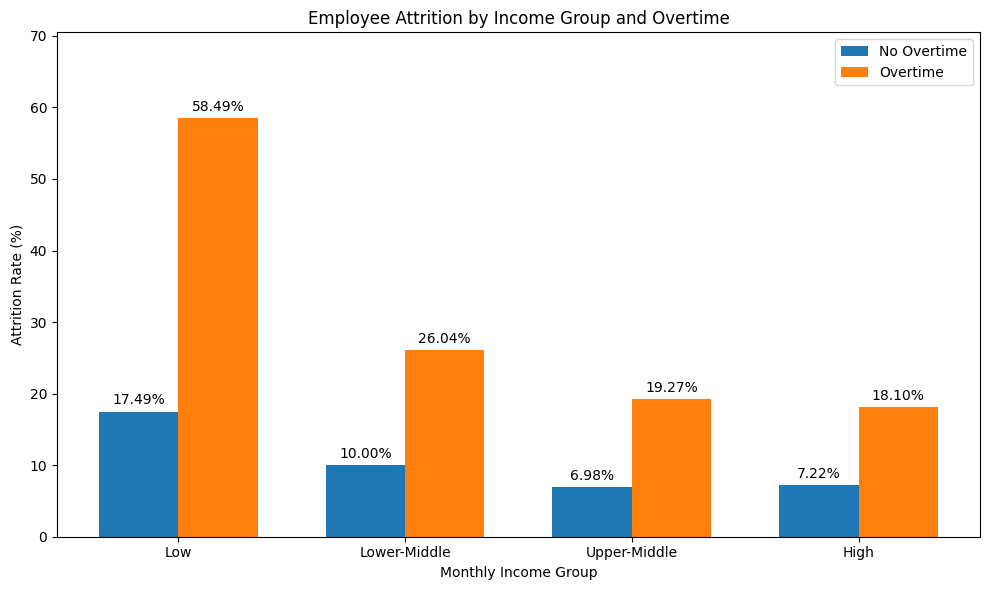

In [33]:

import matplotlib.pyplot as plt
import numpy as np

# Prepare the data for plotting
income_overtime_plot = income_overtime_attrition.reset_index()

income_order = ["Low", "Lower-Middle", "Upper-Middle", "High"]

plot_data = income_overtime_plot.pivot(
    index="IncomeGroup",
    columns="OverTime",
    values="AttritionRate"
).reindex(income_order)

x = np.arange(len(income_order))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 6))

bars_no = ax.bar(
    x - width / 2,
    plot_data["No"],
    width,
    label="No Overtime"
)

bars_yes = ax.bar(
    x + width / 2,
    plot_data["Yes"],
    width,
    label="Overtime"
)

ax.set_title("Employee Attrition by Income Group and Overtime")
ax.set_xlabel("Monthly Income Group")
ax.set_ylabel("Attrition Rate (%)")
ax.set_xticks(x)
ax.set_xticklabels(income_order)
ax.legend()
ax.bar_label(bars_no, fmt="%.2f%%", padding=3)
ax.bar_label(bars_yes, fmt="%.2f%%", padding=3)

ax.set_ylim(0, plot_data.max().max() + 12)
plt.tight_layout()
plt.show()


### Key Findings: Employee Attrition by Income Group and Overtime

The analysis reveals a consistent association between overtime work and higher employee attrition across all four monthly income groups.

- **Low-income employees:** Employees working overtime had an attrition rate of 58.49%, compared with 17.49% among those who did not work overtime. This is the largest difference across the income groups.
- **Lower-middle-income employees:** Attrition reached 26.04% among employees working overtime, compared with 10.00% among those not working overtime.
- **Upper-middle-income employees:** The attrition rate was 19.27% for employees working overtime and 6.98% for those not working overtime.
- **High-income employees:** Employees working overtime had an attrition rate of 18.10%, compared with 7.22% among those who did not work overtime.

**Conclusion:** Employees who work overtime consistently exhibit higher attrition rates, with the strongest difference observed among low-income employees. Lower income combined with overtime may identify a group that warrants closer investigation by HR. However, these descriptive results do not establish causation, and other factors may contribute to employee departures.

## Consolidated Findings

### Employee Experience and Work Conditions

- **Overtime:** Employees working overtime have a substantially higher attrition rate than those who do not, indicating that workload and working arrangements warrant further investigation.
- **Job satisfaction:** Employees with the lowest job satisfaction have the highest attrition rate (22.84%), compared with 11.33% among those with the highest satisfaction.
- **Work-life balance:** Employees reporting the lowest work-life balance have the highest attrition rate (31.25%), compared with 14.22% among those reporting level 3.

### Demographic and Financial Patterns

- **Age:** Employees under 25 have the highest attrition rate (39.18%), followed by employees aged 25–34 (20.22%).
- **Monthly income:** The low-income group has the highest attrition rate (29.27%), while the high-income group has the lowest (10.33%).
- **Income and overtime:** Low-income employees working overtime have an attrition rate of 58.49%, the highest among the income-and-overtime combinations examined.

### Career and Employment Patterns

- **Tenure:** Employees with 0–1 years at the company have the highest attrition rate (34.88%). The rate generally declines with longer tenure, reaching 8.13% among employees with 11 or more years.
- **Job level:** Level 1 employees have the highest attrition rate (26.34%), while level 4 employees have the lowest (4.72%). Level 3 employees show a higher rate (14.68%) than level 2 employees (9.74%).
- **Business travel:** Employees who travel frequently have a higher attrition rate (24.91%) than those who travel rarely (14.96%) or do not travel (8.00%).

### Overall Interpretation

The analysis identifies several employee groups that may warrant further investigation, particularly younger employees, employees with short tenure, employees working overtime, and employees reporting low job satisfaction or work-life balance.

These findings are descriptive associations, not proof of causation. The results should be interpreted alongside group sizes, overlapping employee characteristics, and potential confounding factors. Further analysis can help determine which factors remain associated with attrition when considered together.

In [34]:

# Calculate overall employee attrition metrics

total_employees = len(df)

employees_left = (df["Attrition"] == "Yes").sum()
employees_stayed = (df["Attrition"] == "No").sum()

overall_attrition_rate = (
    employees_left / total_employees * 100
)

retention_rate = (
    employees_stayed / total_employees * 100
)

print("OVERALL EMPLOYEE ATTRITION SUMMARY")
print("-" * 40)
print(f"Total Employees: {total_employees:,}")
print(f"Employees Who Left: {employees_left:,}")
print(f"Employees Who Stayed: {employees_stayed:,}")
print(f"Overall Attrition Rate: {overall_attrition_rate:.2f}%")
print(f"Employee Retention Rate: {retention_rate:.2f}%")


OVERALL EMPLOYEE ATTRITION SUMMARY
----------------------------------------
Total Employees: 1,470
Employees Who Left: 237
Employees Who Stayed: 1,233
Overall Attrition Rate: 16.12%
Employee Retention Rate: 83.88%


### Overall Employee Attrition Baseline

The dataset contains 1,470 employees, of whom 237 left the company and 1,233 remained employed.

| Metric | Result |
|---|---:|
| Total employees | 1,470 |
| Employees who left | 237 |
| Employees who stayed | 1,233 |
| Overall attrition rate | 16.12% |
| Employee retention rate | 83.88% |

The overall attrition rate was calculated by dividing the number of employees who left by the total number of employees. The retention rate was calculated by dividing the number of employees who stayed by the total number of employees.

**Interpretation:** Approximately 16 out of every 100 employees in the dataset left the company, while approximately 84 remained. This baseline provides a reference point for comparing attrition rates across demographic groups, income levels, job characteristics, and working conditions.

These figures describe the observed dataset and should not be interpreted as a forecast of future employee departures.

## Business Recommendations

Based on the exploratory analysis of employee attrition, the following recommendations are proposed to help HR identify retention risks and prioritize further investigation.

### Strengthen Early-Tenure Employee Retention

Employees with 0–1 years of service have an attrition rate of 34.88%, substantially above the overall rate of 16.12%.

**Recommendations:**
- Improve onboarding and orientation programs.
- Assign mentors or experienced colleagues to new employees.
- Conduct regular check-ins during the first year.
- Collect feedback to identify challenges involving training, workload, management, and role expectations.

**Suggested KPI:** Attrition rate among employees with less than two years of service.

### Review Overtime and Workload Practices

Employees who work overtime have an overall attrition rate of 30.53%, compared with 10.44% among employees who do not work overtime.

The low-income group working overtime has an attrition rate of 58.49%, making it a priority for further investigation.

**Recommendations:**
- Review overtime frequency and workload distribution.
- Assess whether overtime compensation is competitive and consistently applied.
- Evaluate staffing levels and opportunities to reduce excessive workloads.
- Examine whether overtime is associated with lower satisfaction or work-life balance.

**Suggested KPI:** Attrition rate by overtime status and the average number of overtime hours per employee, if available.

### Improve Job Satisfaction and Work-Life Balance

Employees with the lowest job satisfaction have an attrition rate of 22.84%, while those with the highest satisfaction have a rate of 11.33%. Employees reporting the lowest work-life balance have an attrition rate of 31.25%.

**Recommendations:**
- Conduct employee engagement surveys and exit interviews.
- Review workload expectations, scheduling flexibility, and management support.
- Develop targeted improvement plans based on employee feedback.
- Track changes in satisfaction and work-life balance over time.

**Suggested KPI:** Attrition rate by satisfaction level and work-life balance rating.

### Investigate Younger Employees' Retention Risks

Employees under 25 have an attrition rate of 39.18%, the highest among the age groups analyzed.

**Recommendations:**
- Investigate whether career development opportunities meet younger employees' expectations.
- Review compensation, training, and advancement pathways.
- Compare age-related attrition patterns with tenure, job level, and job satisfaction before designing targeted interventions.

**Suggested KPI:** Attrition rate by age group and tenure.

### Monitor Attrition Through Regular Reporting

HR should establish a recurring attrition dashboard to monitor overall attrition, retention, and the employee groups with elevated rates.

**Recommendations:**
- Track overall attrition and retention rates.
- Compare attrition across departments, job levels, income groups, age groups, and overtime status.
- Monitor changes monthly or quarterly, depending on data availability.
- Evaluate whether retention initiatives are followed by measurable improvements.

**Suggested KPI:** Overall attrition rate, early-tenure attrition rate, and attrition rate among employees working overtime.

### Recommendation Limitations

These recommendations are based on descriptive patterns in the available dataset. The analysis identifies associations but does not establish causation. HR should validate these findings with additional information, such as exit interview feedback, overtime hours, department-level workload, compensation policies, and employee survey results, before implementing major policy changes.